# $\underline{\text{Modularity Study in Karate Club Graph}}$.
### An attempt to divide the graph into communities based on the concepts of modularity.

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
G = nx.karate_club_graph()

## $\underline{\text{Python Libraries used}}$ :-

NumPy, NetworkX and MatPlotLib are the libraries I import inorder to do this problem. I also import the Karate_club_graph from NetworkX as 'G'

Below, I use draw function from NetworkX to draw my graph with a random seed. I also see that there are 34 nodes and 78 edges in my graph.

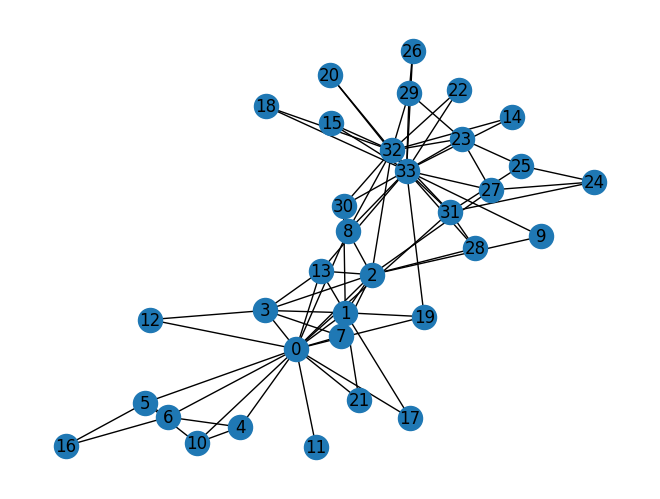

Number of nodes in this graph : 34
Number of edges in this graph : 78


In [2]:
nx.draw(G, with_labels=True)
plt.show()

nodes = G.number_of_nodes()
edges = G.number_of_edges()
print(f"Number of nodes in this graph : {nodes}") 
print(f"Number of edges in this graph : {edges}")

## $\underline{\text{Adjacency Matrix}}$ :-

Ajacency matrix is an $n \times n$ matrix that contains information about the neighbors of an edge. In the original Karate Club graph, Zachary used weighted edges. As in, the edges had information about how strong the friendship between two students were based on how many times they met up outside classes per week. But for this study, we only see whether a friendship exists or not. That is, either 0 or 1. In the code below, I obtain the adjacency matrix of the graph and convert it from fuzzy to crisp using a while-loop.

In [3]:
G_adj = nx.adjacency_matrix(G).toarray()
print("The weighted adjacency matrix is\n")
print(G_adj)

print(f"\n\n(The size of the adjacency matrix is {nodes}x{nodes})")

#Changing the membership value of edge to binary
i = 0
j = 0
while i < nodes:
    while j < nodes:
        if G_adj[i][j] > 0:
            G_adj[i][j] = 1
        else:
            G_adj[j][j] = 0
        j = j + 1
    j = 0
    i = i + 1

print("\n\nThe un-weighted adjacency matrix is \n")
print(G_adj)

The weighted adjacency matrix is

[[0 4 5 ... 2 0 0]
 [4 0 6 ... 0 0 0]
 [5 6 0 ... 0 2 0]
 ...
 [2 0 0 ... 0 4 4]
 [0 0 2 ... 4 0 5]
 [0 0 0 ... 4 5 0]]


(The size of the adjacency matrix is 34x34)


The un-weighted adjacency matrix is 

[[0 1 1 ... 1 0 0]
 [1 0 1 ... 0 0 0]
 [1 1 0 ... 0 1 0]
 ...
 [1 0 0 ... 0 1 1]
 [0 0 1 ... 1 0 1]
 [0 0 0 ... 1 1 0]]


## $\underline{\text{The Assignment Vector}}$

Our next step involves making a guess assignment vector $\vec{s} = \{+1, -1\}_{1 \times n}$ that contains our initial guess about where each node should belong. Then we find the degree vector for each node in our original unweighted graph. This vector contains information about the degree of each node in our original graph.

## $\underline{\text{Random Baseline }}$

A random baseline is obtained by keeping the nodes in their fixed places and moving around the edges such that the degree sequence of the nodes is preserved. The Adjacency matrix for the random baseline is obtained using the fact that the probability that an edge exist between two nodes $i$ and $j$ is proportional to the the number of edges (more precisely half-edges) coming out of node-$i$ $(=k_i)$ and the probability of a stay 'half-edge' getting attached to the one of the $k_j$ half-edges of node-$j$ out of $2m$ total possibilites. The product of the two terms gives us
$$\frac{k_i k_j}{2m}$$

## $\underline{\text{Modularity Matrix}}$

The Modularity Matrix tells us how different our original unweighted adjacency matrix is from the random baseline. That is given by
$$\mathbf{B} = \mathbf{A} - \frac{k^Tk}{2m}$$

In [4]:
degree_vector = np.array([val for (node, val) in G.degree()])
kk_t = np.outer(degree_vector,degree_vector)

rand_baseline_adj = (1/(2*edges))*kk_t

print("The random baseline adjacency matrix below tells how many edges is expects between the i'th and j'th node")
print(rand_baseline_adj)

Modularity_Matrix = G_adj - rand_baseline_adj

print("\n\nThe Modularity Matrix is")
print(Modularity_Matrix)

The random baseline adjacency matrix below tells how many edges is expects between the i'th and j'th node
[[1.64102564 0.92307692 1.02564103 ... 0.61538462 1.23076923 1.74358974]
 [0.92307692 0.51923077 0.57692308 ... 0.34615385 0.69230769 0.98076923]
 [1.02564103 0.57692308 0.64102564 ... 0.38461538 0.76923077 1.08974359]
 ...
 [0.61538462 0.34615385 0.38461538 ... 0.23076923 0.46153846 0.65384615]
 [1.23076923 0.69230769 0.76923077 ... 0.46153846 0.92307692 1.30769231]
 [1.74358974 0.98076923 1.08974359 ... 0.65384615 1.30769231 1.8525641 ]]


The Modularity Matrix is
[[-1.64102564  0.07692308 -0.02564103 ...  0.38461538 -1.23076923
  -1.74358974]
 [ 0.07692308 -0.51923077  0.42307692 ... -0.34615385 -0.69230769
  -0.98076923]
 [-0.02564103  0.42307692 -0.64102564 ... -0.38461538  0.23076923
  -1.08974359]
 ...
 [ 0.38461538 -0.34615385 -0.38461538 ... -0.23076923  0.53846154
   0.34615385]
 [-1.23076923 -0.69230769  0.23076923 ...  0.53846154 -0.92307692
  -0.30769231]
 [-1.74358974

## $\underline{\text{The Modularity Score}}$
The Modularity Score ($Q$) is calculated as follows:
$$Q = \frac{\mathbf{s}^T\mathbf{B}\mathbf{s}}{4m}$$

Our goal is to find the assignment vector that maximizes this modularity score. 

### Problems of using binary assignmnent of community membership value

If were to test out every possible assignment vector, we'd soon run into a problem. There are $2^{34}$ possible combinations to test and it is not an easy task.

### Possible Work-arounds

A possible work-around for this is to relax the assignment vector from being strictly binary, to take any values from the open interval $(-1,+1)$ such that the norm of the assignmet vector is 1. When this is case, I can invoke $\textit{Cayley-Ritz theorem}$ that says that the eigenvector corresponding to the highest eigenvalue is the one that maximizes the modularity score. 

After we obtain the required assignment vector, we can turn it back into binary by rounding off every positive value to 1 and negative value to -1.

----

Below, I have computed the maximum eigenvalue, found the corresponding eigenvector and then coverted it back to ${-1,+1}$


In [5]:
(eigenvalues, eigenvectors) = np.linalg.eig(Modularity_Matrix)

#Obtaining the position of the maximum eigenvalue
max_eigenvalue_pos = np.argmax(eigenvalues)

#Obtaining the value of the maximum eigenvalue
max_eigenvalue = eigenvalues[max_eigenvalue_pos]

#Obtaining the value of eigenvector at the position of max eigenvalue
max_eigenvector = eigenvectors[:, max_eigenvalue_pos] 

print("Maximum Eigenvalue:")
print(max_eigenvalue.real)

print("\nCorresponding Eigenvector :")
print(max_eigenvector.real)

print("\n\nThresholding to {-1, +1}")

Assign_vector = max_eigenvector.real.copy()
i = 0

while i < nodes:
    if max_eigenvector.real[i] > 0:
        Assign_vector[i] = 1
    else:
        Assign_vector[i] = -1
    i = i + 1

print("\n Corresponding Assignment vector : ")
print(Assign_vector)



Maximum Eigenvalue:
4.977080225729909

Corresponding Eigenvector :
[ 0.38754293  0.26955742  0.13189899  0.25345236  0.13400323  0.14573804
  0.14573804  0.20935954 -0.05447571 -0.04785238  0.13400323  0.07784279
  0.12874396  0.13502861 -0.13943288 -0.13943288  0.05851821  0.13197981
 -0.13943288  0.05764888 -0.13943288  0.13197981 -0.13943288 -0.21674712
 -0.0563305  -0.07540039 -0.11580257 -0.10276487 -0.06834027 -0.20629456
 -0.09626391 -0.10185678 -0.32390453 -0.36983786]


Thresholding to {-1, +1}

 Corresponding Assignment vector : 
[ 1.  1.  1.  1.  1.  1.  1.  1. -1. -1.  1.  1.  1.  1. -1. -1.  1.  1.
 -1.  1. -1.  1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1.]


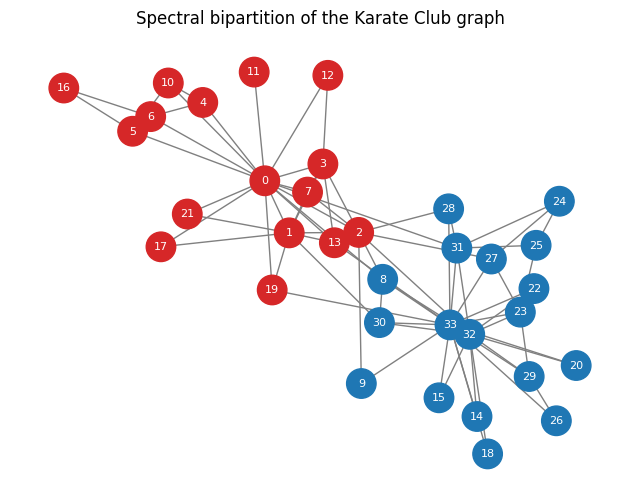

In [6]:
pos = nx.spring_layout(G, seed=29)  

colors = ['tab:red' if s == 1 else 'tab:blue' for s in Assign_vector]

plt.figure(figsize=(8, 6))
nx.draw_networkx(G, pos, node_color=colors, with_labels=True,
                 node_size=450, font_size=8, font_color='white',
                 edge_color='gray')
plt.title("Spectral bipartition of the Karate Club graph")
plt.axis('off')
plt.show()

Up until here the entire code was my own (except the coloring the graph part, I didn't know how to add colors to nodes in code). 

### After this I knew I had to do something similar but iterate it inside a loop that follows the algorithm below

step 1 : divide the graph into subgraphs for each community

step 2 : Obtain the adjacency matrix, random baseline $\rightarrow$ modularity matrix $\rightarrow$ maximum eigenvalue

step 3 : If maximum eigenvalue is positive, find the eigenvector corresponding to that eigenvalue and split the sub-graph using an new assignment vector. If not, retain the original graph.

step 4 : Repeat this process until for every sub-community you obtain, the maximum eigenvalue is negative (or in other words, all eigenvalues are negative).

--------------------------------------

When I did try to this on my own, I ran into two problems...
Firstly, the logic statement of it felt extremely dense and hard to follow through. Especially since the number of iterations depend on the eigenvalues of the previous iteration.

Secondly, when I did try to do the second iteration, it plotted each community as seperate graphs and even if I tried to draw the seperate graphs together, all edges between the different communities were removed and I had no idea how to recover that information.

$\textit{Hence, at this point, I decided to use AI}$ and the following code below is written by Claude (with the exception of a few additions I made manually) based completely on the logical instruction I gave it.

In [7]:
# =============================================================================
# CELL 7 - Recursive spectral modularity splitting of the Karate Club graph (corrected)
#
# Reuses variables from the earlier cells (nothing is redefined, no new imports):
#   np, nx, plt  -> libraries imported in cell 1
#   G            -> the Karate Club graph (cell 1)
#   G_adj        -> binary adjacency matrix (cell 3)
#   Modularity_Matrix -> GLOBAL modularity matrix B = A - k k^T / 2m (cell 5)
#   pos          -> fixed spring layout, seed=29 (cell 6)
#
# FIX vs. the earlier version: when a community g is split, the modularity matrix
# must be built from the WHOLE graph (global degrees k_i and global m), not from the
# edges inside g only. Otherwise the edges that leave g are ignored and lambda_1 > 0
# no longer implies that Q can increase. The correct generalized matrix (Newman 2006) is
#       B^(g)_ij = B_ij - delta_ij * sum_{l in g} B_il          (i, j in g)
# and the modularity change of a split is  dQ = s^T B^(g) s / (4m)  (global m).
# In addition, a split is only accepted if dQ > 0, because rounding u_1 to +-1 can
# lose the gain even when lambda_1 is slightly positive.
#
#
# How the user defined "iteration" here: in each iteration, every community that is
# still divisible (positive eigenvalue exists) is tested once (steps 2-5 of the algorithm). The results of the
# whole round are then drawn and printed. Step 6 (recursion) is the loop that
# keeps testing the newly created sub-communities in the next iteration.
# =============================================================================


# =============================================================================
# SECTION 0 - SETTINGS (change these if you want to tune the behaviour)
# =============================================================================

# Floating-point eigenvalues are never exactly 0, so "lambda_1 <= 0" is tested as
# "lambda_1 <= EIG_TOL".
EIG_TOL = 1e-6

# A split is accepted only if it raises Q by more than this amount.
DQ_TOL = 1e-9

# High-contrast palette: (hex code, readable name).
# Each community label points to ONE entry for the whole run, so a community
# never changes color between iterations.
PALETTE = [
    ("#e6194B", "red"),
    ("#4363d8", "blue"),
    ("#3cb44b", "green"),
    ("#f58231", "orange"),
    ("#911eb4", "purple"),
    ("#000000", "black"),
    ("#f032e6", "magenta"),
    ("#9A6324", "brown"),
    ("#008080", "teal"),
    ("#800000", "maroon"),
    ("#808000", "olive"),
    ("#000075", "navy"),
]


# =============================================================================
# SECTION 1 - NODE METRICS (Enter the additional datas you wanted to compute, here)
# =============================================================================
deg_centrality = nx.degree_centrality(G)
btw_centrality = nx.betweenness_centrality(G)
cls_centrality = nx.closeness_centrality(G)
clustering_coef = nx.clustering(G)


The comments in the Claude-generated-code above and below are retained so as to understand it better and see what each section does. The code below is where all the functions required for our main code is written. 

The function below calculates the modularity matrix for the whole graph. It returns the modularity gain-$\Delta Q$, after each iteration.

$\Delta Q$ is a new concept used to prevent a lone community. Without it, node-11 will be marked as a seperate community with no friends, The $\Delta Q$ addition works as follows

The $\Delta Q$ check asks one thing before splitting the graph -- "Will $Q$ go up when this graph is splitted?"

If the answer is no, irrespective of whether there exists a positive eigenvalue or not, the split is stopped.

In [8]:
def modularity_matrix_of_subgraph(group):
    """Generalized modularity matrix B^(g) of a community g (uses the WHOLE graph)."""
    idx = sorted(group)
    B_sub = Modularity_Matrix[np.ix_(idx, idx)].copy()   # global B restricted to g
    B_sub -= np.diag(B_sub.sum(axis=1))                   # - delta_ij * sum_{l in g} B_il
    return idx, B_sub

The function below (as the name suggests) is what checks and splits the sub-graph further depending on the eigenvalues. If the eigenvalue of a community is negative (more precisely less than a tolerance of $10^{-6}$ that I have set, the community doesn't split. Else, it is forced to split based on the eigenvector of the maximum eigenvalue.

In [9]:
def try_to_split(group):
    # Trivial cases: nothing to split.
    if len(group) < 2:
        return None, None, None, "only one node"

    # STEP 2: generalized modularity matrix of the community.
    idx, B_sub = modularity_matrix_of_subgraph(group)

    # STEP 3: leading eigenpair (lambda_1, u_1).
    # eigh is used because B_sub is symmetric; it returns eigenvalues in
    # ascending order, so the leading one is the LAST column.
    eigenvalues_sub, eigenvectors_sub = np.linalg.eigh(B_sub)
    lam1 = eigenvalues_sub[-1]
    u1 = eigenvectors_sub[:, -1]

    # STEP 4: if lambda_1 <= 0 -> stop, the group is indivisible.
    if lam1 <= EIG_TOL:
        return lam1, None, None, f"lambda_1 = {lam1:.6f} <= 0"

    # STEP 5: split nodes into C+ and C- by the sign of u_1.
    # (Same convention as cell 5: > 0 goes to C+, everything else to C-.)
    c_plus = [node for node, value in zip(idx, u1) if value > 0]
    c_minus = [node for node, value in zip(idx, u1) if value <= 0]

    # Safety check: if every entry of u_1 has the same sign, there is no real split.
    if len(c_plus) == 0 or len(c_minus) == 0:
        return lam1, None, None, "all entries of u_1 have the same sign"

    # STEP 5b: check the ACTUAL modularity gain of the +-1 split.
    # (lambda_1 > 0 only guarantees a gain for the real-valued u_1, not for its sign.)
    plus_set = set(c_plus)
    s = np.array([1.0 if node in plus_set else -1.0 for node in idx])
    delta_Q = s @ B_sub @ s / (4 * edges)
    if delta_Q <= DQ_TOL:
        return lam1, None, None, (f"lambda_1 = {lam1:.6f} > 0 but the split would not "
                                  f"raise Q (dQ = {delta_Q:+.6f})")

    return lam1, c_plus, c_minus, None



This is a modification I made to the code later to display $Q$ after each iteration so that I can ensure it is increasing with each iteration.

In [10]:
def partition_modularity():
    return nx.community.modularity(
        G, [set(members) for members in community_members.values()], weight=None
    )

def modularity_score_binary():
    total = 0.0
    for label, members in community_members.items():
        s = -np.ones(nodes)                 # start with every node as -1
        s[members] = 1                      # nodes in this community become +1
        total += s @ Modularity_Matrix @ s  # s^T B s via matrix multiplication
    return total / (8 * edges)

The code below (again written by Claude) is what draws the graph. I specifically asked it to retain the colors of the communities it made so that when a specific community splits, the sub-community having the more number of nodes retains the original color of the community while the newly formed smaller community gets a new color.

It also makes tables under each graph that calculates degree centrality, betweeness centrality and closeness centrality for each node and clustering coefficient for each community hence formed. 

In [11]:
# =============================================================================
# SECTION 3 - VISUALIZATION HELPER
# =============================================================================

def draw_partition(iteration):
    # Map each node to its community label so we can look up its color.
    node_to_label = {}
    for label, members in community_members.items():
        for node in members:
            node_to_label[node] = label

    # Colors in the same order as G.nodes(), as networkx expects.
    node_color_list = [community_color[node_to_label[node]][0] for node in G.nodes()]

    plt.figure(figsize=(9, 6))
    nx.draw_networkx(
        G, pos,                              
        node_color=node_color_list,
        with_labels=True,                    
        node_size=450, font_size=8, font_color="white",
        edge_color="gray",
    )

    
    for label in sorted(community_members):
        hex_code, color_name = community_color[label]
        plt.plot([], [], "o", color=hex_code,
                 label=f"Community {label} ({color_name}, {len(community_members[label])} nodes)")
    plt.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)

    plt.title(f"Iteration {iteration}: {len(community_members)} communities "
              f"(Q = {partition_modularity():.4f})")
    plt.axis("off")
    plt.show()


# =============================================================================
# SECTION 4 - TABLE HELPERS
# =============================================================================

def print_community_table(label):
    members = sorted(community_members[label])
    color_name = community_color[label][1]

    print(f"\nCommunity {label} ({color_name}) - {len(members)} nodes")
    header = (f"{'Node':>5} | {'Degree Cent.':>12} | {'Betweenness':>11} | "
              f"{'Closeness':>9} | {'Clustering':>10}")
    print(header)
    print("-" * len(header))

    for node in members:
        print(f"{node:>5} | {deg_centrality[node]:>12.4f} | {btw_centrality[node]:>11.4f} | "
              f"{cls_centrality[node]:>9.4f} | {clustering_coef[node]:>10.4f}")

    # Community average (optional summary row).
    print("-" * len(header))
    print(f"{'Mean':>5} | "
          f"{np.mean([deg_centrality[n] for n in members]):>12.4f} | "
          f"{np.mean([btw_centrality[n] for n in members]):>11.4f} | "
          f"{np.mean([cls_centrality[n] for n in members]):>9.4f} | "
          f"{np.mean([clustering_coef[n] for n in members]):>10.4f}")


def report_iteration(iteration):
    """Everything shown after an iteration: the score, the plot, then a table per community."""
    # Modularity score of the whole graph (binary s, numpy matrix multiplication)
    # plus networkx's value as a cross-check.
    print(f"Modularity score  Q = (1/4m) s^T B s : {modularity_score_binary():.4f}"
          f"   (networkx check: {partition_modularity():.4f})")

    draw_partition(iteration)
    print(f"===== Metric tables after iteration {iteration} =====")
    for label in sorted(community_members):
        print_community_table(label)
    print()


The main section of the code runs and it calls the above functions as it requires.

Iteration 0: starting state (all nodes in one community)
Modularity score  Q = (1/4m) s^T B s : 0.0000   (networkx check: 0.0000)


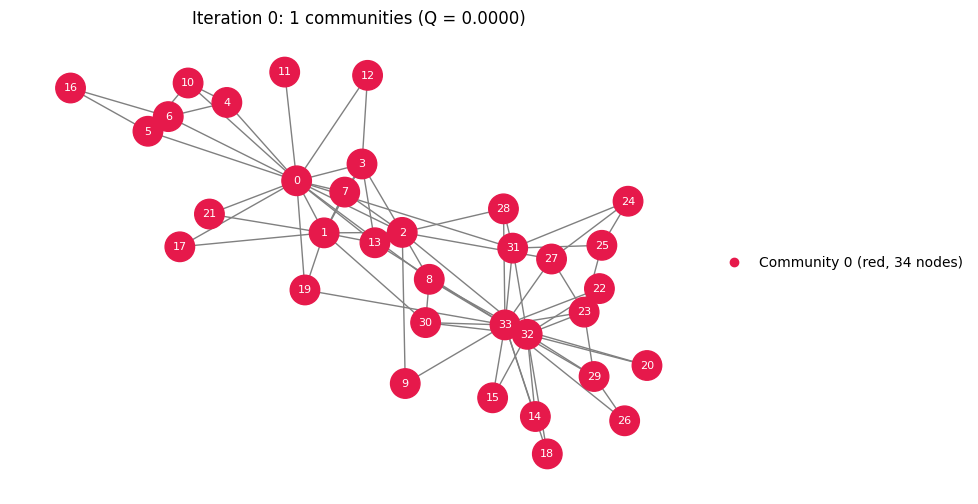

===== Metric tables after iteration 0 =====

Community 0 (red) - 34 nodes
 Node | Degree Cent. | Betweenness | Closeness | Clustering
-----------------------------------------------------------
    0 |       0.4848 |      0.4376 |    0.5690 |     0.1500
    1 |       0.2727 |      0.0539 |    0.4853 |     0.3333
    2 |       0.3030 |      0.1437 |    0.5593 |     0.2444
    3 |       0.1818 |      0.0119 |    0.4648 |     0.6667
    4 |       0.0909 |      0.0006 |    0.3793 |     0.6667
    5 |       0.1212 |      0.0300 |    0.3837 |     0.5000
    6 |       0.1212 |      0.0300 |    0.3837 |     0.5000
    7 |       0.1212 |      0.0000 |    0.4400 |     1.0000
    8 |       0.1515 |      0.0559 |    0.5156 |     0.5000
    9 |       0.0606 |      0.0008 |    0.4342 |     0.0000
   10 |       0.0909 |      0.0006 |    0.3793 |     0.6667
   11 |       0.0303 |      0.0000 |    0.3667 |     0.0000
   12 |       0.0606 |      0.0000 |    0.3708 |     1.0000
   13 |       0.1515 |    

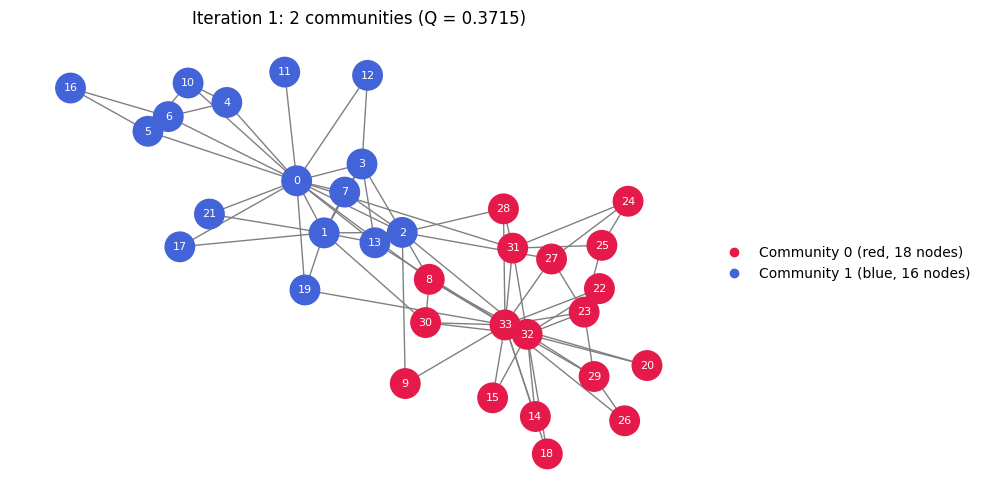

===== Metric tables after iteration 1 =====

Community 0 (red) - 18 nodes
 Node | Degree Cent. | Betweenness | Closeness | Clustering
-----------------------------------------------------------
    8 |       0.1515 |      0.0559 |    0.5156 |     0.5000
    9 |       0.0606 |      0.0008 |    0.4342 |     0.0000
   14 |       0.0606 |      0.0000 |    0.3708 |     1.0000
   15 |       0.0606 |      0.0000 |    0.3708 |     1.0000
   18 |       0.0606 |      0.0000 |    0.3708 |     1.0000
   20 |       0.0606 |      0.0000 |    0.3708 |     1.0000
   22 |       0.0606 |      0.0000 |    0.3708 |     1.0000
   23 |       0.1515 |      0.0176 |    0.3929 |     0.4000
   24 |       0.0909 |      0.0022 |    0.3750 |     0.3333
   25 |       0.0909 |      0.0038 |    0.3750 |     0.3333
   26 |       0.0606 |      0.0000 |    0.3626 |     1.0000
   27 |       0.1212 |      0.0223 |    0.4583 |     0.1667
   28 |       0.0909 |      0.0018 |    0.4521 |     0.3333
   29 |       0.1212 |    

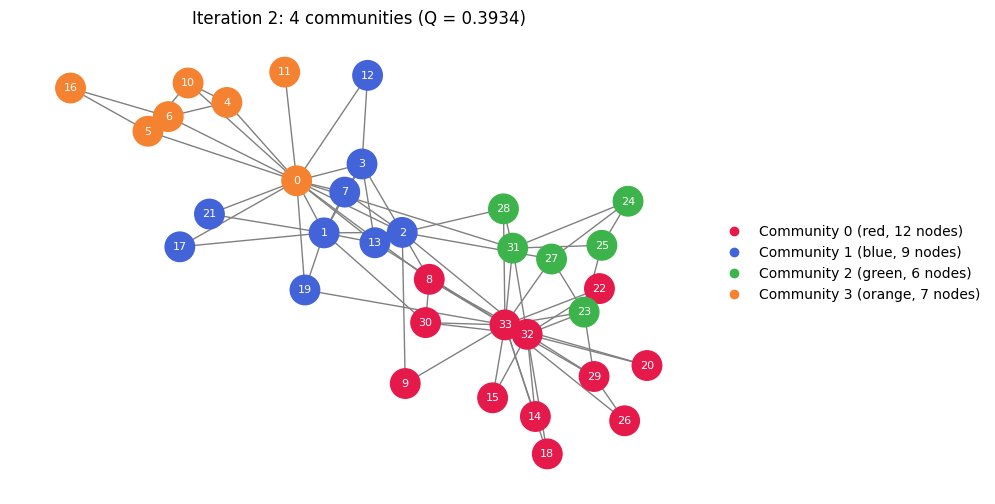

===== Metric tables after iteration 2 =====

Community 0 (red) - 12 nodes
 Node | Degree Cent. | Betweenness | Closeness | Clustering
-----------------------------------------------------------
    8 |       0.1515 |      0.0559 |    0.5156 |     0.5000
    9 |       0.0606 |      0.0008 |    0.4342 |     0.0000
   14 |       0.0606 |      0.0000 |    0.3708 |     1.0000
   15 |       0.0606 |      0.0000 |    0.3708 |     1.0000
   18 |       0.0606 |      0.0000 |    0.3708 |     1.0000
   20 |       0.0606 |      0.0000 |    0.3708 |     1.0000
   22 |       0.0606 |      0.0000 |    0.3708 |     1.0000
   26 |       0.0606 |      0.0000 |    0.3626 |     1.0000
   29 |       0.1212 |      0.0029 |    0.3837 |     0.6667
   30 |       0.1212 |      0.0144 |    0.4583 |     0.5000
   32 |       0.3636 |      0.1452 |    0.5156 |     0.1970
   33 |       0.5152 |      0.3041 |    0.5500 |     0.1103
-----------------------------------------------------------
 Mean |       0.1414 |    

In [12]:
# =============================================================================
# SECTION 5 - STEP 1: START WITH THE FULL NODE SET V
# =============================================================================

community_members = {0: sorted(G.nodes())}
community_color = {0: PALETTE[0]}

next_label = 1            # label that the next newly created community will get
active_labels = [0]       # communities still waiting to be tested
iteration = 0

print("Iteration 0: starting state (all nodes in one community)")
report_iteration(iteration)


# =============================================================================
# SECTION 6 - MAIN LOOP (steps 2-6)
# =============================================================================

while active_labels:
    iteration += 1
    print(f"\n########## Iteration {iteration} ##########")

    newly_active = []         # children created in this iteration (STEP 6: recurse on them)
    split_happened = False

    for label in active_labels:
        group = community_members[label]

        # STEPS 2-5 for this community.
        lam1, c_plus, c_minus, reason = try_to_split(group)

        # STEP 4 outcome: indivisible -> it stays as it is and is never tested again.
        if c_plus is None:
            print(f"  Community {label} ({community_color[label][1]}): "
                  f"indivisible - {reason}.")
            continue

        # STEP 5 outcome: the community splits in two.
        # Color rule: the BIGGER sub-community keeps the original label (and color);
        # the smaller one gets a brand-new label with the next unused color.
        # (On an exact tie, C+ keeps the original; the sign of u_1 is arbitrary anyway.)
        if len(c_plus) >= len(c_minus):
            bigger, smaller = c_plus, c_minus
        else:
            bigger, smaller = c_minus, c_plus

        community_members[label] = sorted(bigger)
        community_members[next_label] = sorted(smaller)
        community_color[next_label] = PALETTE[next_label % len(PALETTE)]

        print(f"  Community {label} ({community_color[label][1]}) splits "
              f"(lambda_1 = {lam1:.4f}): "
              f"{len(bigger)} nodes keep {community_color[label][1]}, "
              f"{len(smaller)} nodes become community {next_label} "
              f"({community_color[next_label][1]}).")

        # STEP 6: both halves must be tested again in the next iteration.
        newly_active += [label, next_label]
        next_label += 1
        split_happened = True

    # Nothing changed in this round -> no new plot/table needed.
    if not split_happened:
        print("  No community could be split any further.")
    else:
        report_iteration(iteration)

    # Only the freshly created communities continue; indivisible ones are done.
    active_labels = newly_active


# =============================================================================
# SECTION 7 - FINAL SUMMARY: {C_1, C_2, ..., C_r}
# =============================================================================

print("\n========== FINAL COMMUNITIES ==========")
for label in sorted(community_members):
    print(f"C{label} ({community_color[label][1]}, {len(community_members[label])} nodes): "
          f"{community_members[label]}")
print(f"Number of communities r = {len(community_members)}")
print(f"Final modularity Q = {partition_modularity():.4f}")

## $\underline{\text{Results and Discussions}}$ :-

The code ran for two iterations giving us a total of 4 communities. After this iteration, the blue community still has one positive eigenvalue that splits it further. But, when this happens, the overall $Q$ of the graph drops and therefore, it is not carried out. 2nd Iteration is thus the last iteration. 

Below given, is the code for plotting the graphs to visualize degree centrality, betweeness centrality, closeness centrality and clustering coefficient with each iteration.

In [13]:
history = [{0: sorted(G.nodes())}]
members = {0: sorted(G.nodes())}
active, nxt = [0], 1

while active:
    new_active, changed = [], False
    for lab in active:
        lam1, c_plus, c_minus, reason = try_to_split(members[lab])
        if c_plus is None:
            continue
        big, small = (c_plus, c_minus) if len(c_plus) >= len(c_minus) else (c_minus, c_plus)
        members[lab], members[nxt] = sorted(big), sorted(small)
        new_active += [lab, nxt]
        nxt += 1
        changed = True
    if changed:
        history.append({k: list(v) for k, v in members.items()})
    active = new_active

n_iter = len(history)
print(f"Recorded {n_iter} partitions (iterations 0 to {n_iter-1})")

# Metrics for every node, measured inside the subgraph of the community it belongs to
metric_names = ["Degree centrality", "Betweenness centrality",
                "Closeness centrality", "Clustering coefficient"]
metric_funcs = [nx.degree_centrality, nx.betweenness_centrality,
                nx.closeness_centrality, nx.clustering]

# metric_history[name][t, i] = value of metric `name` for node i after iteration t
metric_history = {name: np.zeros((n_iter, nodes)) for name in metric_names}

for t, snapshot in enumerate(history):
    for label, comm in snapshot.items():
        H = G.subgraph(comm)
        if H.number_of_nodes() == 1:          # a lone node has no neighbours: all metrics are 0
            for name in metric_names:
                metric_history[name][t, comm[0]] = 0.0
            continue
        for name, func in zip(metric_names, metric_funcs):
            values = func(H)
            for node in comm:
                metric_history[name][t, node] = values[node]

Recorded 3 partitions (iterations 0 to 2)


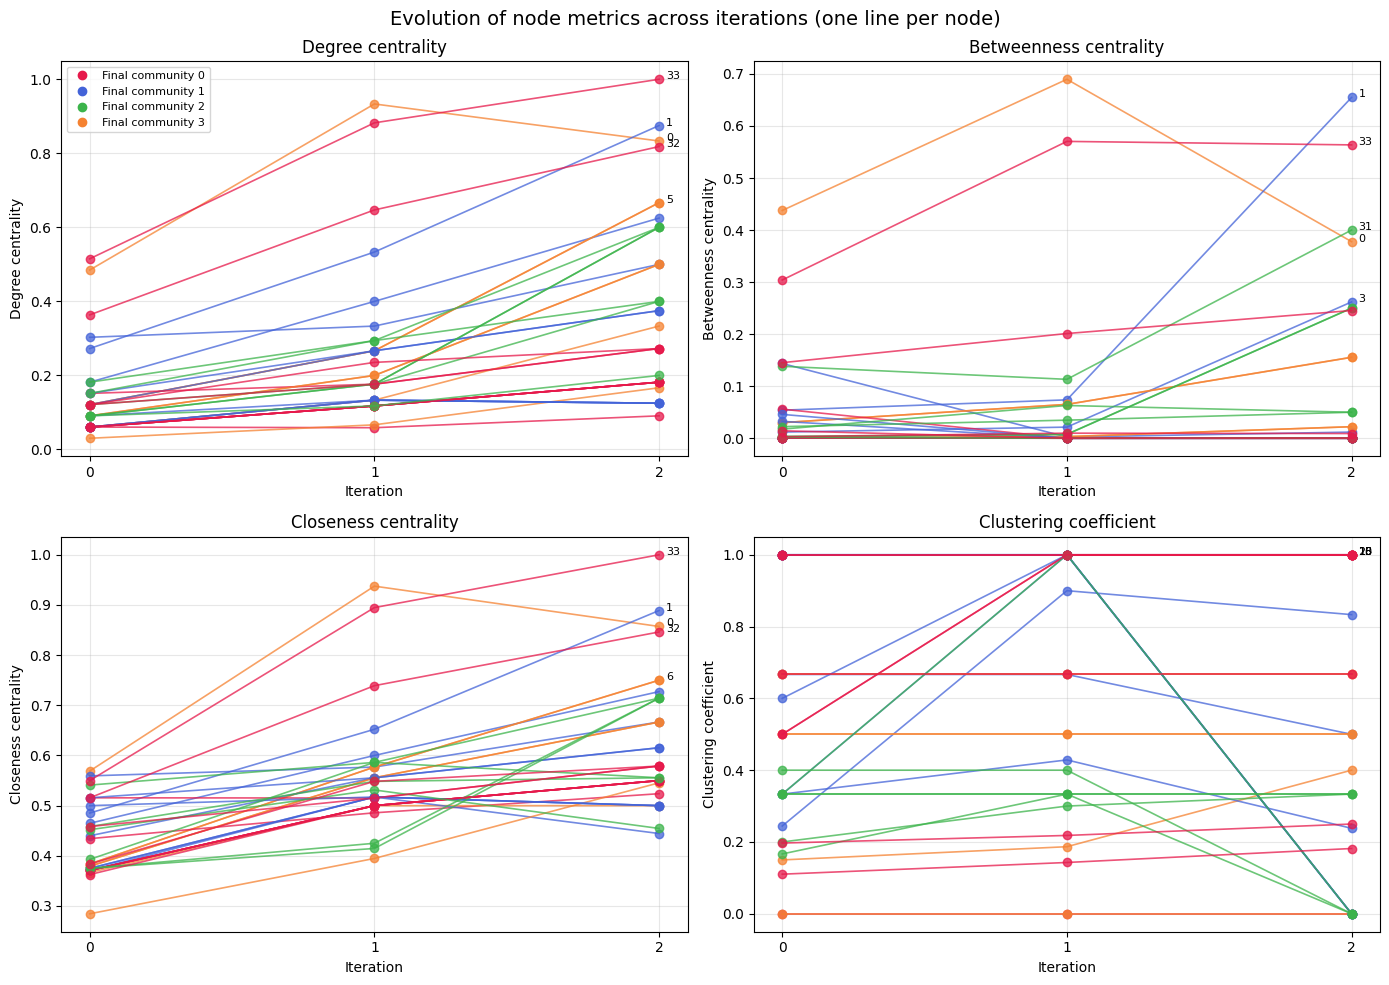

In [14]:
final_label = {}
for label, comm in history[-1].items():
    for node in comm:
        final_label[node] = label

iters = np.arange(n_iter)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, name in zip(axes.ravel(), metric_names):
    data = metric_history[name]
    for node in range(nodes):
        ax.plot(iters, data[:, node], marker="o", lw=1.2, alpha=0.75,
                color=PALETTE[final_label[node] % len(PALETTE)][0])
    # label the 5 highest nodes at the final iteration
    for node in np.argsort(data[-1])[::-1][:5]:
        ax.annotate(str(node), (iters[-1], data[-1, node]),
                    xytext=(5, 0), textcoords="offset points", fontsize=8)
    ax.set_title(name)
    ax.set_xlabel("Iteration")
    ax.set_ylabel(name)
    ax.set_xticks(iters)
    ax.grid(alpha=0.3)

# legend: color = community at the final iteration
for label in sorted(history[-1]):
    axes[0, 0].plot([], [], "o", color=PALETTE[label % len(PALETTE)][0],
                    label=f"Final community {label}")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Evolution of node metrics across iterations (one line per node)", fontsize=14)
plt.tight_layout()
plt.show()

Node 0, 1, 32 and 33 have a comparitively high value of centrality through-out the iterations. 

Clustering coefficient gives the most amount of information. As number of clusters (communities) increased, we got overall tighter clusters. The blue community with 9 nodes and red community with 12 nodes has the highest clustering coefficients of 0.6864 and 0.6645 respectively. Meanwhile the green community with 6 nodes has the lowest clustering coefficient of 0.2944.